# Оценка на качеството на данните по периоди

**Проблемът:** един и същ модел дава `R2 = 0.519` за `Jan–Feb`, но `R2 = -0.981` за `Jan–Mar`.
Причината не е моделът, а **данните** – в някои периоди сензорите лъжат (байпас на вода,
замръзнали тагове, глитчи) и моделът учи шум.

**Идеята:** да не избираме периода "на ръка", а да изчислим **оценка за качеството на всеки
ред / ден** и да обучаваме само върху чистите.

## Слоеве на проверките

1. **На сензор** – липсва проба, замръзнал таг, статистически outlier, физически невъзможна стойност.
2. **Физическа съгласуваност** – байпас на вода (`WaterZumpf/Ore`), воден баланс, специфична енергия, плътност.
3. **Мултивариантни аномалии** – комбинации, които поотделно изглеждат ОК, но заедно са невъзможни.
4. **Shift между периоди** – KS/PSI + adversarial validation: различават ли се периодите по сензори.
5. **Композитен quality score** – едно число `0..1` на ред, агрегирано по дни.
6. **Валидация** – обучение върху всички vs само чисти редове, при **един и същ** test set.

**Ред на изпълнение:** config -> read_raw -> build -> flags -> score -> анализ -> валидация.

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)
plt.rcParams['figure.figsize'] = (14, 4)

ENGINE = create_engine(
    'mssql+pyodbc:///?odbc_connect='
    'DRIVER={ODBC Driver 17 for SQL Server};SERVER=10.20.2.10;'
    'DATABASE=pulse;UID=Pulse_RO;PWD=PD@T@r3@der'
)

# feature -> { MillName: TagID }
SQL_TAGS = {
    'Ore':        {'Mill06': '500',  'Mill07': '455',  'Mill08': '467'},
    'WaterMill':  {'Mill06': '1219', 'Mill07': '461',  'Mill08': '474'},
    'WaterZumpf': {'Mill06': '1220', 'Mill07': '462',  'Mill08': '475'},
    'Power':      {'Mill06': '502',  'Mill07': '460',  'Mill08': '471'},
    'ZumpfLevel': {'Mill06': '501',  'Mill07': '458',  'Mill08': '470'},
    'PressureHC': {'Mill06': '1217', 'Mill07': '459',  'Mill08': '472'},
    'DensityHC':  {'Mill06': '1216', 'Mill07': '457',  'Mill08': '469'},
    'FE':         {'Mill06': '1762', 'Mill07': '1762', 'Mill08': '1762'},
    'PulpHC':     {'Mill06': '2777', 'Mill07': '2837', 'Mill08': '1833'},
    'PumpRPM':    {'Mill06': '2796', 'Mill07': '2856', 'Mill08': '1800'},
    'MotorAmp':   {'Mill06': '2770', 'Mill07': '2830', 'Mill08': '1805'},
    'PSI200':     {'Mill06': '5328', 'Mill07': '5330', 'Mill08': '5333'},
}

TABLE_NAMES = ['LoggerValues'] + [
    f'LoggerValues_Archive_{m}{y}'
    for y in (2026, 2025)
    for m in ('Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec')
    if not (y == 2026 and m in ('Oct', 'Nov', 'Dec'))
]

TARGET = 'PSI200'
# всички сензори, които проверяваме за качество (вкл. тези, които не влизат в модела)
SENSORS = [f for f in SQL_TAGS if f != TARGET]
# features, които реално влизат в модела (същите като в dataframe_test.ipynb)
MODEL_FEATURES = ['Ore', 'WaterMill', 'WaterZumpf', 'PressureHC', 'DensityHC', 'PulpHC', 'MotorAmp']

# физически "невъзможни" граници - всичко извън тях е сигурно лошо
PHYSICAL_LIMITS = {
    'Ore':        (0, 400),
    'WaterMill':  (0, 100),
    'WaterZumpf': (0, 600),
    'Power':      (0, 4000),
    'ZumpfLevel': (0, 3000),
    'PressureHC': (0, 2),
    'DensityHC':  (1000, 2200),
    'FE':         (0, 100),
    'PulpHC':     (0, 1200),
    'PumpRPM':    (0, 1000),
    'MotorAmp':   (0, 500),
    'PSI200':     (10, 40),
}

# --- сравнение на периоди (shift) ---
# None  -> автоматично: първата половина от заредения период vs втората
# 'дата' -> преди датата vs след нея (напр. '2026-03-01')
SHIFT_SPLIT = None
# под този брой редове в някой от периодите сравнението се пропуска (иначе KS/PSI = NaN)
MIN_PERIOD_ROWS = 50

print(f'{len(SENSORS)} сензора за проверка, {len(MODEL_FEATURES)} в модела')
print('SENSORS:', SENSORS)

11 сензора за проверка, 7 в модела
SENSORS: ['Ore', 'WaterMill', 'WaterZumpf', 'Power', 'ZumpfLevel', 'PressureHC', 'DensityHC', 'FE', 'PulpHC', 'PumpRPM', 'MotorAmp']


In [66]:
def read_raw(start=None, end=None):
    """Сурови данни: {feature: {mill: Series}}. Без resample, без ffill."""
    tag_map = {}
    for feat, mills in SQL_TAGS.items():
        for mill, tag in mills.items():
            tag_map.setdefault(tag, []).append((feat, mill))

    tags = ','.join(tag_map)
    frames = []
    for tbl in TABLE_NAMES:
        q = f'SELECT IndexTime, LoggerTagID, Value FROM {tbl} WHERE LoggerTagID IN ({tags})'
        if start:
            q += f' AND IndexTime >= {start!r}'
        if end:
            q += f' AND IndexTime < {end!r}'
        d = pd.read_sql_query(q, ENGINE)
        print(f'{tbl:<32} {len(d):>8}')
        if not d.empty:
            frames.append(d)

    raw = pd.concat(frames, ignore_index=True)
    raw['LoggerTagID'] = raw['LoggerTagID'].astype(str)
    raw['IndexTime'] = pd.to_datetime(raw['IndexTime'])
    # dedup по (време, таг) - иначе при еднакъв IndexTime губим мелници
    raw = raw.drop_duplicates(['IndexTime', 'LoggerTagID'], keep='last').sort_values('IndexTime')

    out = {}
    for tag, targets in tag_map.items():
        s = raw.loc[raw['LoggerTagID'] == tag].set_index('IndexTime')['Value'].sort_index()
        s = s[~s.index.duplicated(keep='last')]
        for feat, mill in targets:
            out.setdefault(feat, {})[mill] = s
    return out


def build(raw, mill, lag=0, max_gap=60):
    """1 ред на PSI200 четене; features = mean/std/n/frozen в интервала до предишното четене."""
    psi = raw[TARGET][mill].dropna()
    edges = (psi.index - pd.Timedelta(minutes=lag)).values
    n = len(psi) - 1

    out = pd.DataFrame(index=psi.index[1:])
    out.index.name = 'TimeStamp'
    out[TARGET] = psi.values[1:]
    out['dt_sec'] = np.diff(psi.index.values) / np.timedelta64(1, 's')

    for feat in SENSORS:
        s = raw.get(feat, {}).get(mill)
        if s is None or s.dropna().empty:
            out[f'{feat}_mean'] = np.nan
            out[f'{feat}_std'] = np.nan
            out[f'{feat}_n'] = 0
            out[f'{feat}_frozen'] = True
            continue

        s = s.dropna()
        # в кой прозорец попада всяка сурова стойност
        pos = np.searchsorted(edges, s.index.values, side='left') - 1
        ok = (pos >= 0) & (pos < n)
        g = pd.DataFrame({'pos': pos[ok], 'v': s.values[ok]}).groupby('pos')['v']
        st = pd.DataFrame({'mean': g.mean(), 'std': g.std(), 'n': g.count()}).reindex(range(n))

        out[f'{feat}_mean'] = st['mean'].values
        out[f'{feat}_std'] = st['std'].values
        out[f'{feat}_n'] = st['n'].fillna(0).astype(int).values
        # замръзнал: >1 проба, но всички еднакви
        out[f'{feat}_frozen'] = ((st['n'] > 1) & (st['std'].fillna(0) == 0)).values

    out['n_features_ok'] = out[[f'{f}_mean' for f in SENSORS]].notna().sum(axis=1)
    if max_gap:
        out = out[out['dt_sec'] <= max_gap * 60]
    return out

## 1. Флагове на ниво сензор

За всяка feature проверяваме 4 неща:

- **missing** – в прозореца няма нито една сурова проба (`_n == 0`).
- **frozen** – замръзнал таг: или всички проби в прозореца са еднакви (`_frozen`),
  или стойността не се е променила в последните `n` четения.
- **outlier** – робустен z-score спрямо плъзгаща се медиана/MAD (`|z| > 4`).
  Робустен, защото не се влияе от самите аномалии (за разлика от mean/std).
- **range** – физически невъзможна стойност (`PHYSICAL_LIMITS`).

За target-а отделно: **glitch** (PSI200 извън `[10, 40]`, напр. 6553) и **flat** (дълга поредица еднакви стойности).

In [67]:
def robust_z(s, window='7D', min_periods=30):
    """Робустен z-score: (x - rolling median) / (1.4826 * rolling MAD)."""
    med = s.rolling(window, min_periods=min_periods, center=True).median()
    mad = (s - med).abs().rolling(window, min_periods=min_periods, center=True).median()
    scale = (1.4826 * mad).replace(0, np.nan)
    return (s - med) / scale


def frozen_run(s, n=6, tol=1e-9):
    """True, ако стойността не се е променила в последните n четения (замръзнал сензор)."""
    same = s.diff().abs() <= tol
    return same.rolling(n, min_periods=n).sum() >= (n - 1)


def add_sensor_flags(df, min_coverage=0.5):
    """Флагове за всеки сензор: missing / frozen / outlier / range + target glitch/flat.

    Сензори с покритие < min_coverage се пропускат (иначе FE/PumpRPM биха
    държали quality score изкуствено нисък през целия период).
    """
    out = df.copy()
    flags = pd.DataFrame(index=out.index)
    skipped = []

    for f in SENSORS:
        m = out.get(f'{f}_mean')
        if m is None:
            continue
        if m.notna().mean() < min_coverage:
            skipped.append(f)
            continue
        n = out.get(f'{f}_n', pd.Series(1, index=out.index))

        flags[f'{f}_missing'] = (n == 0)
        frz = out.get(f'{f}_frozen', pd.Series(False, index=out.index))
        # ВАЖНО: _frozen_flag, а не _frozen - build() вече има колона _frozen
        flags[f'{f}_frozen_flag'] = frz | frozen_run(m)
        flags[f'{f}_outlier'] = robust_z(m).abs() > 4
        lo, hi = PHYSICAL_LIMITS.get(f, (-np.inf, np.inf))
        flags[f'{f}_range'] = (m < lo) | (m > hi)

    psi = out[TARGET]
    lo, hi = PHYSICAL_LIMITS[TARGET]
    flags['PSI200_glitch'] = (psi < lo) | (psi > hi)
    flags['PSI200_flat'] = frozen_run(psi, n=8)

    out = pd.concat([out, flags], axis=1)
    out['n_flags'] = flags.sum(axis=1)
    out['n_checks'] = flags.shape[1]
    return out, flags, skipped

## 2. Физическа съгласуваност (най-важният слой)

Тук хващаме това, което статистиката пропуска – **сензорът работи, но лъже**.

- **Байпас на вода в зумпфа** – при частичен байпас реалният дебит е по-голям от отчетения,
  т.е. отчетеното разреждане `WaterZumpf / Ore` пада рязко спрямо обичайното за мелницата.
  Флаг при `robust_z(dilution_zumpf) < -3`.
- **Воден баланс** – `WaterMill / WaterZumpf` трябва да е стабилно; силно отклонение = проблем.
- **Специфична енергия** – `Power / Ore`; отклонение = различна руда или грешен дебит.
- **Плътност** – `DensityHC - PulpHC` трябва да е положителна и стабилна.
- **Работеща мелница** – `Ore > 100 & Power > 1000 & MotorAmp > 100`; иначе редът е спиране/преход.

In [68]:
def add_physical_checks(df):
    """Проверки за физическа съгласуваност между сензорите."""
    out = df.copy()
    eps = 1e-6
    flags = pd.DataFrame(index=out.index)

    ore = out['Ore_mean']
    wm = out['WaterMill_mean']
    wz = out['WaterZumpf_mean']

    # --- разреждане (вода на тон руда) ---
    dil_z = wz / (ore + eps)
    dil_m = wm / (ore + eps)
    out['dilution_zumpf'] = dil_z
    out['dilution_mill'] = dil_m
    out['dilution_total'] = (wm + wz) / (ore + eps)

    # байпас: разреждането в зумпфа е МНОГО под обичайното (z < -3)
    flags['bypass_water'] = robust_z(dil_z) < -3

    # --- воден баланс: WaterMill / WaterZumpf трябва да е стабилно ---
    ratio = wm / (wz + eps)
    out['water_ratio'] = ratio
    flags['water_imbalance'] = robust_z(ratio).abs() > 4

    # --- специфична енергия: Power / Ore ---
    spec = out['Power_mean'] / (ore + eps)
    out['spec_energy'] = spec
    flags['spec_energy_outlier'] = robust_z(spec).abs() > 4

    # --- консистентност на плътността: DensityHC - PulpHC ---
    dp = out['DensityHC_mean'] - out['PulpHC_mean']
    out['density_minus_pulp'] = dp
    flags['density_inconsistent'] = robust_z(dp).abs() > 4

    # --- мелницата работи ли ---
    running = (ore > 100) & (out['Power_mean'] > 1000) & (out['MotorAmp_mean'] > 100)
    out['mill_running'] = running
    flags['mill_stopped'] = ~running

    out = pd.concat([out, flags], axis=1)
    return out, flags

## 3. Мултивариантни аномалии

Понякога всеки сензор поотделно е в норма, но **комбинацията** е невъзможна
(напр. висок дебит вода при ниско ниво на зумпфа). Затова:

- робустно стандартизираме `_mean` колоните (median / IQR),
- `IsolationForest` дава `anomaly_score` (по-високо = по-аномално),
- флагваме ~2% най-аномални редове.

In [69]:
from sklearn.ensemble import IsolationForest


def add_multivariate_flags(df, contamination=0.02, random_state=42):
    """Мултивариантни аномалии по _mean колоните на моделните features."""
    out = df.copy()
    cols = [f'{f}_mean' for f in MODEL_FEATURES if f'{f}_mean' in out.columns]
    X = out[cols].astype(float)

    # робустно стандартизиране (median/IQR), за да не доминират големите мащаби
    med = X.median()
    iqr = (X.quantile(0.75) - X.quantile(0.25)).replace(0, np.nan)
    Xs = ((X - med) / iqr).fillna(0.0)

    iso = IsolationForest(contamination=contamination, random_state=random_state, n_jobs=-1)
    iso.fit(Xs)
    out['anomaly_score'] = -iso.score_samples(Xs)   # по-високо = по-аномално
    out['anomaly_flag'] = iso.predict(Xs) == -1
    return out

## 4. Shift между периоди

Отговор на въпроса "защо един период е по-лош от друг".

- **KS + PSI** за всяка feature между два периода – кои сензори са се изместили.
- **Adversarial validation** – може ли класификатор да различи двата периода по сензорите?
  `AUC ≈ 0.5` -> периодите са еднакви; `AUC > 0.8` -> силен shift (различен режим/дефектен сензор).
  Feature importance показва **кой** сензор издава периода.

Периодите **не са hardcode-нати**: `SHIFT_SPLIT` в config клетката задава границата
(`None` = автоматично средата на заредения период, или дата, напр. `'2026-03-01'`).
Така проверката работи за какъвто и период да пуснеш `START`/`END`.

In [70]:
from scipy.stats import ks_2samp


def psi(expected, actual, bins=10):
    """Population Stability Index между две извадки."""
    expected = expected.dropna()
    actual = actual.dropna()
    if len(expected) < 10 or len(actual) < 10:
        return np.nan
    qs = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    if len(qs) < 3:
        return np.nan
    e = np.histogram(expected, bins=qs)[0] / len(expected)
    a = np.histogram(actual, bins=qs)[0] / len(actual)
    e = np.clip(e, 1e-6, None)
    a = np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))


def _as_mask(mask, index):
    """Привежда маска (Series/np.array) към Series с подадения index."""
    return pd.Series(np.asarray(mask), index=index)


def period_shift(df, ref_mask, cmp_mask, min_rows=MIN_PERIOD_ROWS):
    """KS + PSI за всяка моделна feature между два периода.

    Ако някой от периодите е под min_rows, връща NaN за статистиките вместо
    да гърми/връща подвеждащ резултат (n_ref/n_cmp показват защо).
    """
    ref_mask = _as_mask(ref_mask, df.index)
    cmp_mask = _as_mask(cmp_mask, df.index)
    rows = []
    for f in MODEL_FEATURES:
        c = f'{f}_mean'
        if c not in df.columns:
            continue
        a = df.loc[ref_mask, c].dropna()
        b = df.loc[cmp_mask, c].dropna()
        row = {'feature': f, 'n_ref': len(a), 'n_cmp': len(b),
               'mean_ref': a.mean(), 'mean_cmp': b.mean(),
               'ks_stat': np.nan, 'ks_p': np.nan, 'psi': np.nan}
        if len(a) >= min_rows and len(b) >= min_rows:
            ks = ks_2samp(a, b)
            row.update(ks_stat=ks.statistic, ks_p=ks.pvalue, psi=psi(a, b))
        rows.append(row)
    return pd.DataFrame(rows).sort_values('psi', ascending=False)


from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold


def adversarial_validation(df, ref_mask, cmp_mask, min_rows=MIN_PERIOD_ROWS, random_state=42):
    """AUC на класификатор, който различава двата периода по сензорите.

    Връща (auc, importance). auc = NaN, ако периодът е твърде малък или в него
    има само един клас (иначе predict_proba гърми с shape (n, 1)).
    """
    cols = [f'{f}_mean' for f in MODEL_FEATURES if f'{f}_mean' in df.columns]
    ref_mask = _as_mask(ref_mask, df.index)
    cmp_mask = _as_mask(cmp_mask, df.index)
    both = ref_mask | cmp_mask
    d = df.loc[both, cols].copy()
    y = cmp_mask.loc[both].astype(int)

    n_ref, n_cmp = int((y == 0).sum()), int((y == 1).sum())
    if min(n_ref, n_cmp) < min_rows:
        return np.nan, pd.Series(dtype=float)

    d = d.fillna(d.median())
    clf = RandomForestClassifier(n_estimators=200, max_depth=6,
                                 random_state=random_state, n_jobs=-1)

    # ръчно CV: пропускаме фолдове, в които test-ът е само с един клас
    skf = StratifiedKFold(n_splits=min(5, n_ref, n_cmp), shuffle=True,
                          random_state=random_state)
    aucs = []
    for tr, te in skf.split(d, y):
        if y.iloc[te].nunique() < 2:
            continue
        m = clone(clf).fit(d.iloc[tr], y.iloc[tr])
        aucs.append(roc_auc_score(y.iloc[te], m.predict_proba(d.iloc[te])[:, 1]))
    auc = float(np.mean(aucs)) if aucs else np.nan

    clf.fit(d, y)
    imp = pd.Series(clf.feature_importances_, index=cols).sort_values(ascending=False)
    return auc, imp

## 5. Композитен quality score

Сглобяваме всички флагове в едно число `0..1` на ред:

```
quality = 1 - (претеглена сума на флаговете) / (сума на теглата)
```

После агрегираме по дни, за да видим **кога** данните са лоши.
`quality_gate()` връща маска за обучение.

In [71]:
def composite_score(df, sensor_flags, phys_flags, weights=None):
    """Сглобява всички флагове в един quality_score (0..1) на ред."""
    all_flags = pd.concat([sensor_flags, phys_flags], axis=1)
    if 'anomaly_flag' in df.columns:
        all_flags['anomaly'] = df['anomaly_flag']

    if weights is None:
        weights = pd.Series(1.0, index=all_flags.columns)
    w = weights.reindex(all_flags.columns).fillna(1.0)

    penalty = (all_flags.astype(float) * w).sum(axis=1)
    score = 1.0 - penalty / w.sum()
    return score.clip(0, 1), all_flags


def quality_gate(df, min_score=0.9):
    """Маска: True за редове, които са достатъчно чисти за обучение."""
    return df['quality'] >= min_score

## 6. Пълният pipeline за един период

Смени `START`, `END`, `MILL` и пусни всичко надолу.

In [72]:
START, END = '2026-01-01', '2026-02-28'
MILL = 'Mill06'

raw = read_raw(START, END)
df = build(raw, MILL)

df, sensor_flags, skipped = add_sensor_flags(df)
df, phys_flags = add_physical_checks(df)
df = add_multivariate_flags(df)
score, all_flags = composite_score(df, sensor_flags, phys_flags)
df['quality'] = score

print(f'Редове: {len(df)}   период: {df.index.min()} .. {df.index.max()}')
print(f'Пропуснати сензори (покритие < 50%): {skipped}')
print(f'Средно качество: {score.mean():.3f}   чисти редове (>=0.9): {(score >= 0.9).mean() * 100:.1f}%')
print()
print('Дял на всеки флаг (%):')
print((all_flags.mean() * 100).sort_values(ascending=False).round(1).to_string())

LoggerValues                            0
LoggerValues_Archive_Jan2026      3250466
LoggerValues_Archive_Feb2026      2914418
LoggerValues_Archive_Mar2026            0
LoggerValues_Archive_Apr2026            0
LoggerValues_Archive_May2026            0
LoggerValues_Archive_Jun2026            0
LoggerValues_Archive_Jul2026            0
LoggerValues_Archive_Aug2026            0
LoggerValues_Archive_Sep2026            0
LoggerValues_Archive_Jan2025            0
LoggerValues_Archive_Feb2025            0
LoggerValues_Archive_Mar2025            0
LoggerValues_Archive_Apr2025            0
LoggerValues_Archive_May2025            0
LoggerValues_Archive_Jun2025            0
LoggerValues_Archive_Jul2025            0
LoggerValues_Archive_Aug2025            0
LoggerValues_Archive_Sep2025            0
LoggerValues_Archive_Oct2025            0
LoggerValues_Archive_Nov2025            0
LoggerValues_Archive_Dec2025            0
Редове: 6506   период: 2026-01-01 00:22:20.573000 .. 2026-02-27 23:48:21.843

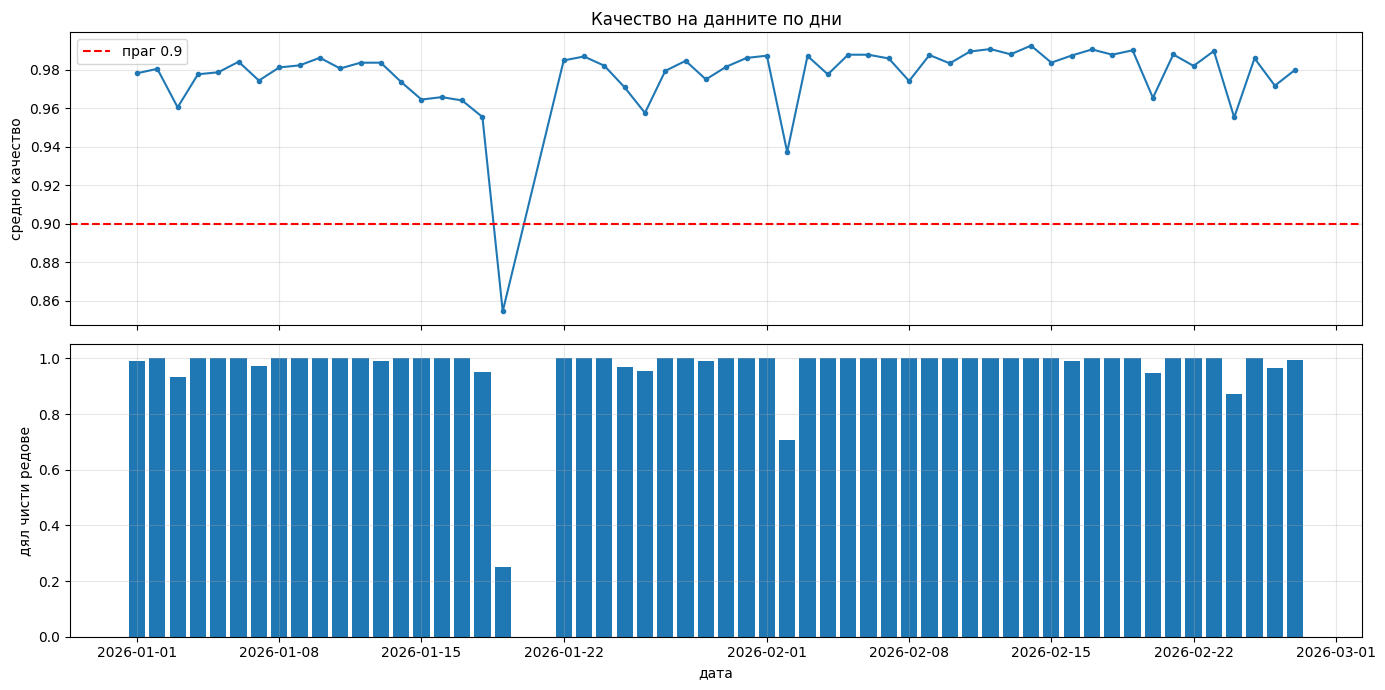

Най-лоши дни:
            quality  clean_frac    n
TimeStamp                           
2026-01-19    0.855       0.250   20
2026-02-02    0.937       0.707  133
2026-02-24    0.955       0.871  132
2026-01-18    0.955       0.951  122
2026-01-26    0.958       0.955  112
2026-01-03    0.960       0.935  107
2026-01-17    0.964       1.000  105
2026-01-15    0.965       1.000   91
2026-02-20    0.965       0.949  117
2026-01-16    0.966       1.000   95


In [73]:
# Качество по дни
daily = pd.DataFrame({
    'quality': df['quality'].resample('1D').mean(),
    'clean_frac': (df['quality'] >= 0.9).resample('1D').mean(),
    'n': df['quality'].resample('1D').count(),
})
daily = daily[daily['n'] > 0]

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(daily.index, daily['quality'], marker='o', ms=3)
axes[0].axhline(0.9, color='r', ls='--', label='праг 0.9')
axes[0].set_ylabel('средно качество')
axes[0].set_title('Качество на данните по дни')
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].bar(daily.index, daily['clean_frac'], width=0.8)
axes[1].set_ylabel('дял чисти редове')
axes[1].set_xlabel('дата')
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()

print('Най-лоши дни:')
print(daily.sort_values('quality').head(10).round(3).to_string())

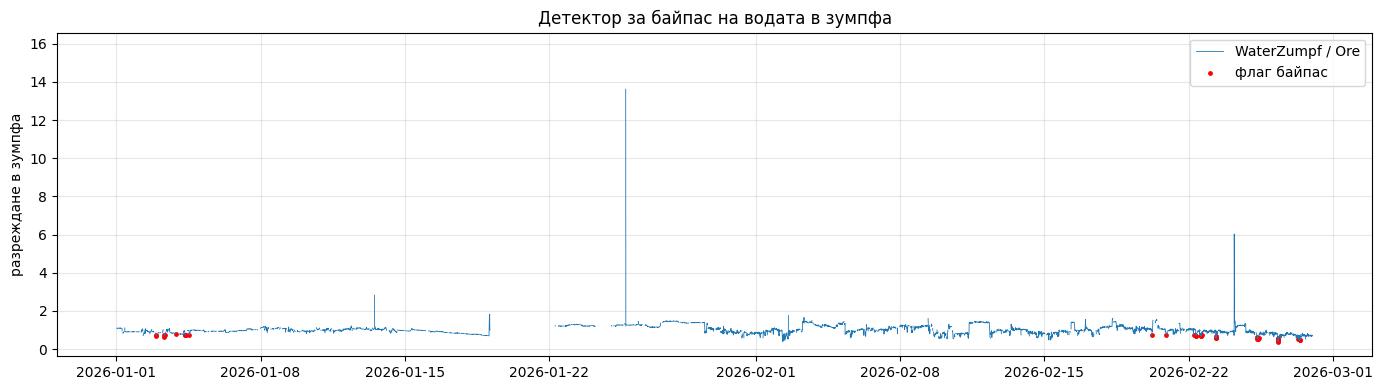

Флагнати редове (байпас): 38 (0.6%)


In [74]:
# Детектор за байпас на водата в зумпфа
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df['dilution_zumpf'], lw=.6, label='WaterZumpf / Ore')
bad = df['bypass_water']
ax.scatter(df.index[bad], df['dilution_zumpf'][bad], s=6, color='r', label='флаг байпас')
ax.set_ylabel('разреждане в зумпфа')
ax.set_title('Детектор за байпас на водата в зумпфа')
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

print(f'Флагнати редове (байпас): {int(bad.sum())} ({bad.mean() * 100:.1f}%)')

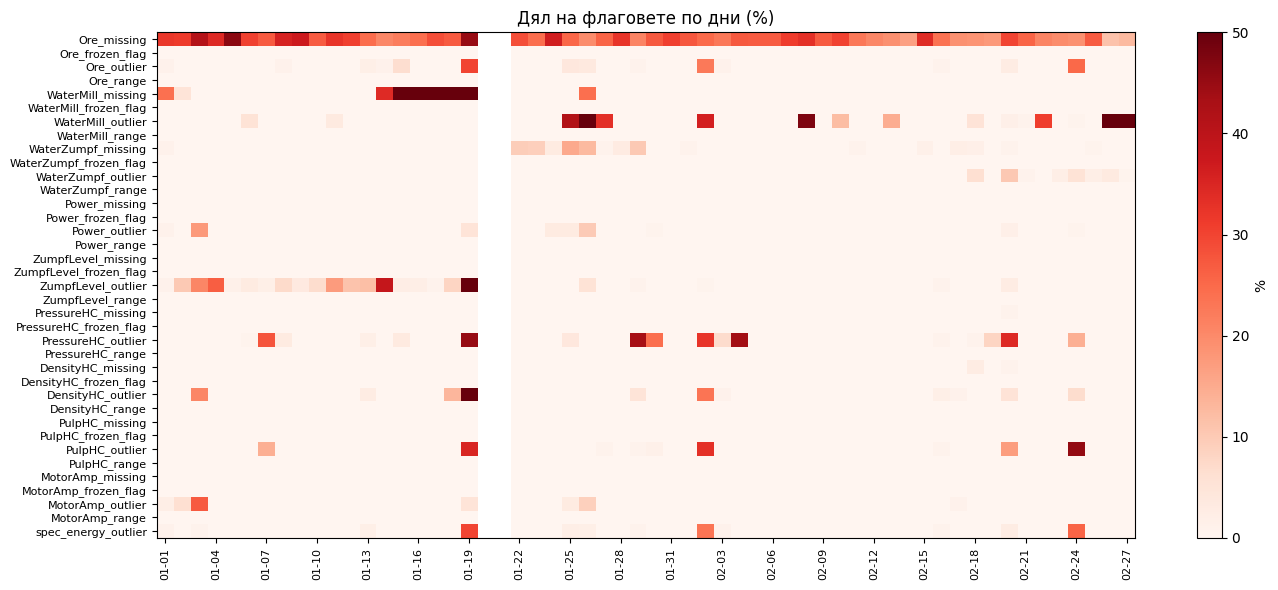

In [75]:
# Дял на флаговете по дни за всеки сензор
flag_cols = [c for c in all_flags.columns
             if c.endswith(('_missing', '_frozen_flag', '_outlier', '_range'))]
by_day = all_flags[flag_cols].resample('1D').mean() * 100

fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(by_day.T.values, aspect='auto', cmap='Reds', vmin=0, vmax=50)
ax.set_yticks(range(len(flag_cols)))
ax.set_yticklabels(flag_cols, fontsize=8)
step = max(1, len(by_day) // 15)
ax.set_xticks(range(0, len(by_day), step))
ax.set_xticklabels([d.strftime('%m-%d') for d in by_day.index[::step]], rotation=90, fontsize=8)
ax.set_title('Дял на флаговете по дни (%)')
fig.colorbar(im, ax=ax, label='%')
plt.tight_layout()
plt.show()

## 7. Сравнение на два периода от заредения диапазон

Тук виждаме **защо** единият период е по-лош: сравняваме разпределенията и правим
adversarial validation. Ако `AUC` е висок, моделът във втория период вижда режим,
който не е учил.

Границата идва от `SHIFT_SPLIT` (config клетката):
`None` -> първата половина от `START..END` vs втората, или дата -> преди/след нея.
Смени `SHIFT_SPLIT` (или `START`/`END`) и пусни клетката – работи за всеки период.

In [76]:
def split_periods(df, split=None):
    """Дели заредения период на две части за сравнение.

    split=None  -> първата половина от периода vs втората (по средата на времето)
    split='дата' -> преди датата vs след нея

    Връща (ref_mask, cmp_mask, label_ref, label_cmp) - етикетите са реалните
    граници на данните, а не hardcode-нати месеци.
    """
    if split is None:
        mid = df.index.min() + (df.index.max() - df.index.min()) / 2
    else:
        mid = pd.Timestamp(split)

    ref = df.index < mid
    cmp = df.index >= mid
    fmt = '%Y-%m-%d %H:%M'
    lab_ref = f'{df.index[ref].min():{fmt}} .. {df.index[ref].max():{fmt}}'
    lab_cmp = f'{df.index[cmp].min():{fmt}} .. {df.index[cmp].max():{fmt}}'
    return ref, cmp, lab_ref, lab_cmp


ref, cmp, lab_ref, lab_cmp = split_periods(df, SHIFT_SPLIT)

print(f'=== Shift между периоди (split={SHIFT_SPLIT or "auto: средата на периода"}) ===')
print(f'  ref: {lab_ref}   ({int(ref.sum())} реда)')
print(f'  cmp: {lab_cmp}   ({int(cmp.sum())} реда)')
print()

if min(ref.sum(), cmp.sum()) < MIN_PERIOD_ROWS:
    print(f'⚠ Единият период е под {MIN_PERIOD_ROWS} реда -> сравнението се пропуска.')
else:
    print(period_shift(df, ref, cmp).round(3).to_string(index=False))
    print()

    auc, imp = adversarial_validation(df, ref, cmp)
    if np.isnan(auc):
        print('Adversarial validation: недостатъчно данни за AUC.')
    else:
        print(f'Adversarial validation AUC = {auc:.3f}   (0.5 = еднакви, >0.8 = силен shift)')
        print('Кои сензори издават периода:')
        print(imp.round(3).to_string())
    print()

    print('Средно качество:')
    print(f'  ref: {df.loc[ref, "quality"].mean():.3f}   '
          f'clean>=0.9: {(df.loc[ref, "quality"] >= 0.9).mean() * 100:.1f}%')
    print(f'  cmp: {df.loc[cmp, "quality"].mean():.3f}   '
          f'clean>=0.9: {(df.loc[cmp, "quality"] >= 0.9).mean() * 100:.1f}%')

=== Shift между периоди (split=auto: средата на периода) ===
  ref: 2026-01-01 00:22 .. 2026-01-29 23:58   (2769 реда)
  cmp: 2026-01-30 00:06 .. 2026-02-27 23:48   (3737 реда)

   feature  n_ref  n_cmp  mean_ref  mean_cmp  ks_stat  ks_p   psi
  MotorAmp   2769   3737   202.284   191.599    0.714   0.0 9.980
       Ore   1950   2848   172.353   168.482    0.432   0.0 1.688
 WaterMill   2250   3737     8.744    11.566    0.497   0.0 1.653
PressureHC   2769   3736     0.453     0.420    0.329   0.0 1.151
    PulpHC   2769   3737   466.335   493.449    0.273   0.0 0.620
 DensityHC   2769   3733  1661.067  1661.326    0.180   0.0 0.403
WaterZumpf   2704   3727   179.101   163.667    0.241   0.0 0.327

Adversarial validation AUC = 1.000   (0.5 = еднакви, >0.8 = силен shift)
Кои сензори издават периода:
MotorAmp_mean      0.427
WaterMill_mean     0.153
PulpHC_mean        0.116
PressureHC_mean    0.112
Ore_mean           0.083
WaterZumpf_mean    0.056
DensityHC_mean     0.053

Средно качество

## 8. Валидация: помага ли филтърът?

Правилният експеримент: **един и същ test set** (последните 20% по време), но
**различен train set** – всички редове vs само чистите. Ако филтърът работи,
`RMSE`/`R2` върху test трябва да се подобрят.

Освен това показваме метриките върху **всички** vs **само чисти** test редове.
Така виждаш дали лошият `R2` идва от мръсните редове в test-а (тогава моделът е ОК,
проблемът е в оценката), или моделът наистина не хваща зависимостта.

In [77]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


def rmse(a, b):
    return mean_squared_error(a, b) ** 0.5


def train_eval(df, test_frac=0.2, clean_thr=0.9):
    """Сравнява XGBoost при един и същ test set.

    Показва две неща:
      - помага ли чистенето на TRAIN (train = всички vs само чисти);
      - колко от лошия R2 идва от мръсните редове в TEST
        (метрики върху всички vs само чисти test редове).
    """
    cols = [f'{f}_mean' for f in MODEL_FEATURES]
    d = df[df[TARGET].between(*PHYSICAL_LIMITS[TARGET])].dropna(subset=cols + [TARGET]).sort_index()
    k = int(len(d) * (1 - test_frac))
    train_all, test = d.iloc[:k], d.iloc[k:]
    test_clean = test[test['quality'] >= clean_thr]

    def fit_eval(train, name):
        m = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6,
                         subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
                         reg_lambda=1.0, objective='reg:squarederror',
                         tree_method='hist', random_state=42, n_jobs=-1)
        m.fit(train[cols], train[TARGET])
        rows = []
        subsets = [('всички', test)]
        if len(test_clean):
            subsets.append(('чисти', test_clean))
        for sub_name, sub in subsets:
            p = m.predict(sub[cols])
            rows.append({'train': name, 'test': sub_name,
                         'n_train': len(train), 'n_test': len(sub),
                         'rmse': rmse(sub[TARGET], p),
                         'mae': mean_absolute_error(sub[TARGET], p),
                         'r2': r2_score(sub[TARGET], p)})
        return rows

    rows = fit_eval(train_all, 'всички')
    for thr in (0.9, 0.95):
        rows += fit_eval(train_all[train_all['quality'] >= thr], f'quality>={thr}')
    return pd.DataFrame(rows)


print(train_eval(df).round(3).to_string(index=False))

        train   test  n_train  n_test  rmse   mae    r2
       всички всички     3482     871 2.196 1.718 0.498
       всички  чисти     3482     856 2.185 1.704 0.493
 quality>=0.9 всички     3449     871 2.306 1.823 0.447
 quality>=0.9  чисти     3449     856 2.289 1.807 0.444
quality>=0.95 всички     3406     871 2.464 1.970 0.368
quality>=0.95  чисти     3406     856 2.437 1.947 0.370


Корелация (грешка по ден vs качество по ден): -0.272
(отрицателна = по-ниско качество -> по-голяма грешка, т.е. филтърът работи)


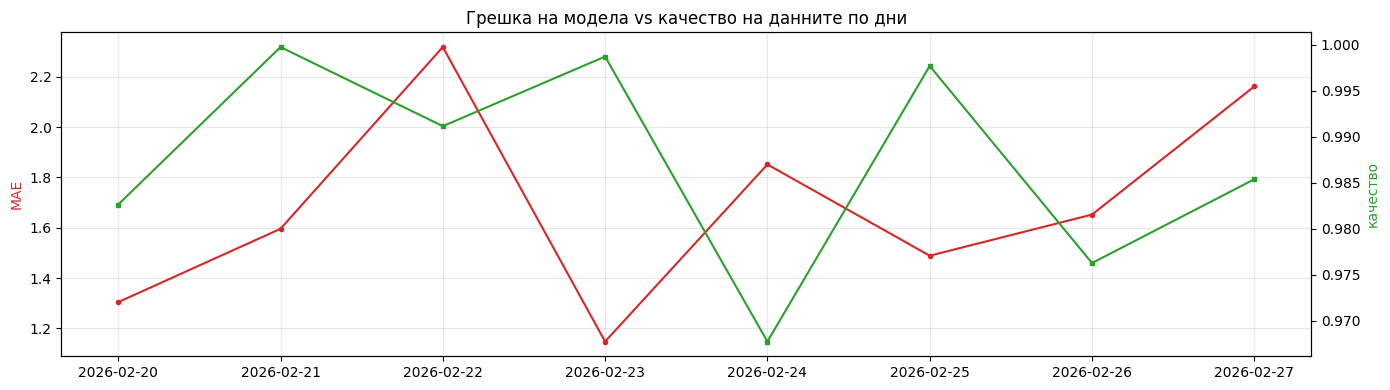

In [78]:
# Грешка на модела по дни vs качество по дни
cols = [f'{f}_mean' for f in MODEL_FEATURES]
d = df[df[TARGET].between(*PHYSICAL_LIMITS[TARGET])].dropna(subset=cols + [TARGET]).sort_index()
k = int(len(d) * 0.8)
tr, te = d.iloc[:k], d.iloc[k:]

m = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6,
                 subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
                 reg_lambda=1.0, objective='reg:squarederror',
                 tree_method='hist', random_state=42, n_jobs=-1)
m.fit(tr[cols], tr[TARGET])
te = te.copy()
te['pred'] = m.predict(te[cols])
te['abs_err'] = (te[TARGET] - te['pred']).abs()

err_day = te['abs_err'].resample('1D').mean()
q_day = te['quality'].resample('1D').mean()
corr = err_day.corr(q_day)
print(f'Корелация (грешка по ден vs качество по ден): {corr:.3f}')
print('(отрицателна = по-ниско качество -> по-голяма грешка, т.е. филтърът работи)')

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(err_day.index, err_day.values, marker='o', ms=3, color='tab:red', label='MAE по дни')
ax2 = ax.twinx()
ax2.plot(q_day.index, q_day.values, color='tab:green', marker='s', ms=3, label='качество')
ax.set_ylabel('MAE', color='tab:red')
ax2.set_ylabel('качество', color='tab:green')
ax.set_title('Грешка на модела vs качество на данните по дни')
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 9. Обобщение и как да го използваме

**Какво правим:**

1. `add_sensor_flags` – хваща липси, замръзнали тагове, outliers, физически невъзможни стойности.
2. `add_physical_checks` – хваща **байпас на вода** (`WaterZumpf/Ore`), воден дисбаланс,
   странна специфична енергия, неконсистентна плътност, спряла мелница.
3. `add_multivariate_flags` – хваща невъзможни комбинации между сензорите.
4. `period_shift` + `adversarial_validation` – показват **кой период и кой сензор** се разминава.
5. `composite_score` – дава `quality` на ред; `quality_gate(df, 0.9)` – маска за обучение.
6. `train_eval` – доказва, че филтърът подобрява модела при **един и същ** test set.

**Практически workflow:**

- Пусни notebook-а за широк период (напр. цялата 2026) и виж `daily['quality']`.
- Дни с `quality < 0.9` или висок дял на `bypass_water` -> **изключи от обучение**.
- Ако `adversarial AUC` между train и test е висок -> имаш covariate shift; или разшири
  train периода, или обучи отделен модел за режима.
- Пази `quality` като колона в датасета, за да може всеки модел да филтрира сам.

**Следващи стъпки (по желание):**

- Тегла по `quality` вместо hard cut (`sample_weight=quality`).
- Отделен "bypass" модел: предсказва `WaterZumpf` от останалите сензори и флагва големи residuals
  (виртуален сензор – хваща и байпас, и дрейф).
- Автоматичен отчет: за всеки месец – `quality`, топ флагове, `adversarial AUC` спрямо предходния.